# UCS420 – Cognitive Computing | Assignment 10
## Diabetes Care Information Assistant (Odd Roll Number)
Name : Aarav Bansal

Roll no : 1024170349


In [2]:
!pip -q install nltk scikit-learn pandas matplotlib seaborn

## 1. Install and import libraries


In [1]:
import re
import warnings
warnings.filterwarnings("ignore")

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import wordpunct_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Labelled corpus (60 queries, 6 intent categories)

In [3]:
data = {
    "diabetes_basics": [
        "What is diabetes?",
        "Explain type 1 diabetes.",
        "What is type 2 diabetes?",
        "How does insulin work in the body?",
        "What happens when blood sugar stays high?",
        "Can you explain gestational diabetes?",
        "What is the difference between type 1 and type 2 diabetes?",
        "Why does the body need insulin?",
        "Is diabetes a long term condition?",
        "Tell me the basic meaning of blood glucose."
    ],
    "symptoms": [
        "What are common signs of diabetes?",
        "Why am I feeling thirsty all the time?",
        "Can frequent urination be a diabetes symptom?",
        "Does diabetes cause unusual hunger?",
        "Can blurred vision be related to high blood sugar?",
        "Why do people with diabetes feel tired?",
        "What are early warning signs of type 2 diabetes?",
        "Can unexplained weight loss happen in diabetes?",
        "Do slow healing cuts relate to diabetes?",
        "What symptoms can high blood glucose cause?"
    ],
    "blood_glucose_monitoring": [
        "How can I monitor my blood sugar at home?",
        "What is a glucometer used for?",
        "When should I check my glucose level?",
        "What does an HbA1c test measure?",
        "How do I keep a record of blood sugar readings?",
        "Why is regular glucose monitoring important?",
        "What is a fasting blood glucose test?",
        "Can I track my glucose readings in a diary?",
        "What should I ask my doctor about my HbA1c result?",
        "How often should a person with diabetes review glucose readings?"
    ],
    "diet_and_lifestyle": [
        "What foods are suitable for someone with diabetes?",
        "How does exercise help manage diabetes?",
        "Why is portion control important?",
        "Can whole grains be part of a diabetes-friendly diet?",
        "What are some healthy snack ideas for diabetes?",
        "Why should sugary drinks be limited?",
        "How can I plan balanced meals?",
        "Does walking help with blood sugar management?",
        "Why is maintaining a healthy weight useful?",
        "What lifestyle habits support diabetes care?"
    ],
    "medication_and_treatment": [
        "What is insulin therapy?",
        "Why might a doctor prescribe metformin?",
        "Should I stop my diabetes medicine if I feel better?",
        "Can you explain diabetes treatment options?",
        "Why is it important to take prescribed medicine as directed?",
        "What should I discuss with my doctor about side effects?",
        "Can diabetes treatment include lifestyle changes?",
        "Who decides the correct insulin dose?",
        "What should I do if I forget a prescribed dose?",
        "Can a pharmacist explain how to store my medicine?"
    ],
    "complications_and_prevention": [
        "What complications can diabetes cause?",
        "How can diabetes affect the eyes?",
        "Why is foot care important for people with diabetes?",
        "Can diabetes affect kidney health?",
        "How can I reduce the risk of diabetes complications?",
        "Why should people with diabetes have regular eye checks?",
        "What is diabetic neuropathy?",
        "How does high blood sugar affect the heart?",
        "Why are regular medical checkups important?",
        "How can I protect my feet if I have diabetes?"
    ]
}

records = [{"query": q, "intent": intent}
           for intent, queries in data.items() for q in queries]
df = pd.DataFrame(records)
print("Total queries:", len(df))
print("Intent categories:", df["intent"].nunique())
display(df.groupby("intent").size().to_frame("number_of_queries"))
display(df.head(10))

Total queries: 60
Intent categories: 6


,number_of_queries
intent,
blood_glucose_monitoring,10
complications_and_prevention,10
diabetes_basics,10
diet_and_lifestyle,10
medication_and_treatment,10
symptoms,10


,query,intent
0,What is diabetes?,diabetes_basics
1,Explain type 1 diabetes.,diabetes_basics
2,What is type 2 diabetes?,diabetes_basics
3,How does insulin work in the body?,diabetes_basics
4,What happens when blood sugar stays high?,diabetes_basics
5,Can you explain gestational diabetes?,diabetes_basics
6,What is the difference between type 1 and type...,diabetes_basics
7,Why does the body need insulin?,diabetes_basics
8,Is diabetes a long term condition?,diabetes_basics
9,Tell me the basic meaning of blood glucose.,diabetes_basics


## 3. Hierarchical taxonomy


In [4]:
taxonomy = {
    "Diabetes Fundamentals": {
        "Types and definitions": ["diabetes_basics"],
        "Insulin and blood glucose": ["diabetes_basics"]
    },
    "Recognition and Monitoring": {
        "Signs and symptoms": ["symptoms"],
        "Glucose tests and tracking": ["blood_glucose_monitoring"]
    },
    "Care and Management": {
        "Food and nutrition": ["diet_and_lifestyle"],
        "Physical activity and habits": ["diet_and_lifestyle"],
        "Medicines and treatment discussions": ["medication_and_treatment"]
    },
    "Long-term Health": {
        "Possible complications": ["complications_and_prevention"],
        "Risk reduction and preventive care": ["complications_and_prevention"]
    }
}

for major, subcategories in taxonomy.items():
    print(major)
    for sub, intents in subcategories.items():
        print("  -", sub, "->", ", ".join(intents))

Diabetes Fundamentals
  - Types and definitions -> diabetes_basics
  - Insulin and blood glucose -> diabetes_basics
Recognition and Monitoring
  - Signs and symptoms -> symptoms
  - Glucose tests and tracking -> blood_glucose_monitoring
Care and Management
  - Food and nutrition -> diet_and_lifestyle
  - Physical activity and habits -> diet_and_lifestyle
  - Medicines and treatment discussions -> medication_and_treatment
Long-term Health
  - Possible complications -> complications_and_prevention
  - Risk reduction and preventive care -> complications_and_prevention


## 4. Domain concepts and relationships


In [5]:
concepts = {
    "Diabetes": "A group of conditions involving elevated blood glucose.",
    "Blood glucose": "The amount of glucose (sugar) present in the blood.",
    "Insulin": "A hormone that helps glucose move from blood into cells.",
    "Pancreas": "An organ that produces insulin.",
    "Glucose meter": "A device used to measure blood glucose.",
    "HbA1c": "A blood test reflecting average blood glucose over roughly the previous 2–3 months.",
    "Nutrition": "Food choices and eating patterns that influence health and glucose management.",
    "Physical activity": "Movement and exercise that can support general health and glucose management.",
    "Medication": "Treatment prescribed by a qualified healthcare professional.",
    "Complications": "Health problems that may develop when diabetes is not well managed over time."
}

relationships = [
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "helps regulate", "Blood glucose"),
    ("Diabetes", "involves abnormal regulation of", "Blood glucose"),
    ("Glucose meter", "measures", "Blood glucose"),
    ("HbA1c", "provides an estimate of longer-term", "Blood glucose"),
    ("Nutrition", "can influence", "Blood glucose"),
    ("Physical activity", "can support management of", "Blood glucose"),
    ("Medication", "may be prescribed to manage", "Diabetes"),
    ("Diabetes", "may lead to", "Complications"),
    ("Regular monitoring", "helps track", "Blood glucose"),
    ("Preventive care", "can help reduce risk of", "Complications")
]

print("Number of concepts:", len(concepts))
print("Number of relationships:", len(relationships))
for name, definition in concepts.items():
    print(f"- {name}: {definition}")
print("\nRelationships:")
for source, relation, target in relationships:
    print(f"- {source} --{relation}--> {target}")

Number of concepts: 10
Number of relationships: 11
- Diabetes: A group of conditions involving elevated blood glucose.
- Blood glucose: The amount of glucose (sugar) present in the blood.
- Insulin: A hormone that helps glucose move from blood into cells.
- Pancreas: An organ that produces insulin.
- Glucose meter: A device used to measure blood glucose.
- HbA1c: A blood test reflecting average blood glucose over roughly the previous 2–3 months.
- Nutrition: Food choices and eating patterns that influence health and glucose management.
- Physical activity: Movement and exercise that can support general health and glucose management.
- Medication: Treatment prescribed by a qualified healthcare professional.
- Complications: Health problems that may develop when diabetes is not well managed over time.

Relationships:
- Pancreas --produces--> Insulin
- Insulin --helps regulate--> Blood glucose
- Diabetes --involves abnormal regulation of--> Blood glucose
- Glucose meter --measures--> Bloo

## 5. Text preprocessing


In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()                         # lowercase conversion
    tokens = wordpunct_tokenize(text)           # tokenization
    tokens = [t for t in tokens if t.isalpha()] # keep alphabetic tokens
    tokens = [t for t in tokens if t not in stop_words]  # stopword removal
    tokens = [lemmatizer.lemmatize(t) for t in tokens]   # lemmatization
    return " ".join(tokens)

df["processed_query"] = df["query"].apply(preprocess_text)
display(df[["query", "processed_query", "intent"]].head(12))

,query,processed_query,intent
0,What is diabetes?,diabetes,diabetes_basics
1,Explain type 1 diabetes.,explain type diabetes,diabetes_basics
2,What is type 2 diabetes?,type diabetes,diabetes_basics
3,How does insulin work in the body?,insulin work body,diabetes_basics
4,What happens when blood sugar stays high?,happens blood sugar stay high,diabetes_basics
5,Can you explain gestational diabetes?,explain gestational diabetes,diabetes_basics
6,What is the difference between type 1 and type...,difference type type diabetes,diabetes_basics
7,Why does the body need insulin?,body need insulin,diabetes_basics
8,Is diabetes a long term condition?,diabetes long term condition,diabetes_basics
9,Tell me the basic meaning of blood glucose.,tell basic meaning blood glucose,diabetes_basics


## 6. TF-IDF feature extraction and intent classification


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["processed_query"], df["intent"],
    test_size=0.25, random_state=42, stratify=df["intent"]
)

vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

classifier = LogisticRegression(max_iter=1000, random_state=42)
classifier.fit(X_train_tfidf, y_train)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("TF-IDF feature count:", X_train_tfidf.shape[1])

Training samples: 45
Testing samples: 15
TF-IDF feature count: 229


## 7. Model evaluation


Accuracy : 0.467
Precision: 0.500
Recall   : 0.467
F1-score : 0.460

Classification report:
                              precision    recall  f1-score   support

    blood_glucose_monitoring       1.00      1.00      1.00         2
complications_and_prevention       0.17      0.50      0.25         2
             diabetes_basics       0.50      0.33      0.40         3
          diet_and_lifestyle       0.00      0.00      0.00         3
    medication_and_treatment       1.00      0.67      0.80         3
                    symptoms       0.33      0.50      0.40         2

                    accuracy                           0.47        15
                   macro avg       0.50      0.50      0.48        15
                weighted avg       0.50      0.47      0.46        15



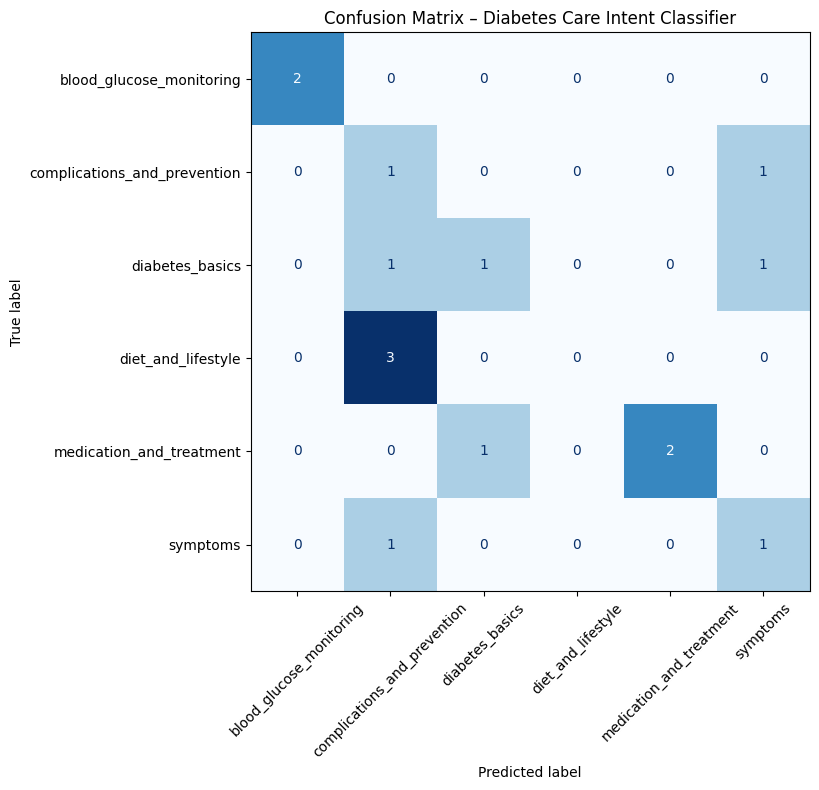

In [8]:
y_pred = classifier.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(11, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix – Diabetes Care Intent Classifier")
plt.tight_layout()
plt.show()

## 8. Diabetes-specific knowledge base


In [9]:
knowledge_base = {
    "diabetes_basics": (
        "Diabetes is a condition in which blood glucose levels are higher than normal "
        "because the body does not make enough insulin or cannot use insulin effectively. "
        "Common forms include type 1, type 2, and gestational diabetes. A healthcare "
        "professional can explain an individual's diagnosis and test results."
    ),
    "symptoms": (
        "Possible symptoms include increased thirst, frequent urination, increased hunger, "
        "unexplained weight changes, fatigue, blurred vision, and slow-healing sores. "
        "Some people have few or no symptoms. Symptoms alone cannot confirm diabetes; "
        "testing and clinical assessment are needed."
    ),
    "blood_glucose_monitoring": (
        "Blood glucose may be checked using a glucose meter or other device recommended "
        "by a healthcare professional. HbA1c is a laboratory test that reflects average "
        "blood glucose over approximately 2–3 months. Follow the monitoring schedule "
        "provided by your care team and keep a record of results."
    ),
    "diet_and_lifestyle": (
        "A balanced eating pattern, appropriate portions, regular physical activity, "
        "adequate sleep, and avoiding tobacco can support overall health and diabetes "
        "management. Individual meal and activity plans should account for personal "
        "health needs and be discussed with a qualified professional."
    ),
    "medication_and_treatment": (
        "Diabetes treatment may include lifestyle support, tablets, injectable medicines, "
        "or insulin, depending on the person and type of diabetes. Take medicines only "
        "as prescribed. Do not start, stop, or change a medicine or dose based on this "
        "assistant; contact your doctor or pharmacist for medicine-specific advice."
    ),
    "complications_and_prevention": (
        "Over time, diabetes can increase the risk of problems involving the eyes, kidneys, "
        "nerves, heart, blood vessels, and feet. Regular checkups, recommended screening, "
        "foot care, and a care plan agreed with a healthcare professional can help reduce "
        "risk and identify problems early."
    )
}

for intent, answer in knowledge_base.items():
    print(f"\n{intent}:\n{answer}")


diabetes_basics:
Diabetes is a condition in which blood glucose levels are higher than normal because the body does not make enough insulin or cannot use insulin effectively. Common forms include type 1, type 2, and gestational diabetes. A healthcare professional can explain an individual's diagnosis and test results.

symptoms:
Possible symptoms include increased thirst, frequent urination, increased hunger, unexplained weight changes, fatigue, blurred vision, and slow-healing sores. Some people have few or no symptoms. Symptoms alone cannot confirm diabetes; testing and clinical assessment are needed.

blood_glucose_monitoring:
Blood glucose may be checked using a glucose meter or other device recommended by a healthcare professional. HbA1c is a laboratory test that reflects average blood glucose over approximately 2–3 months. Follow the monitoring schedule provided by your care team and keep a record of results.

diet_and_lifestyle:
A balanced eating pattern, appropriate portions, 

## 9. Rule-based reasoning and safety rules


In [10]:
EMERGENCY_TERMS = [
    "unconscious", "passed out", "not responding", "seizure",
    "severe difficulty breathing", "can't breathe", "cannot breathe",
    "chest pain", "severe confusion"
]

MEDICATION_CHANGE_TERMS = [
    "change my dose", "increase my dose", "decrease my dose",
    "double my dose", "stop my medicine", "stop taking insulin",
    "what dose should i take"
]

DIABETES_SCOPE_TERMS = [
    "diabetes", "diabetic", "blood sugar", "blood glucose", "glucose",
    "insulin", "hba1c", "glucometer", "metformin", "diabetes medicine",
    "diabetes medication", "high sugar", "low sugar"
]

def is_emergency(query):
    q = query.lower()
    return any(term in q for term in EMERGENCY_TERMS)

def is_medication_change_request(query):
    q = query.lower()
    return any(term in q for term in MEDICATION_CHANGE_TERMS)

def is_in_scope(query):
    q = query.lower()
    return any(term in q for term in DIABETES_SCOPE_TERMS)

def emergency_response():
    return (
        "EMERGENCY WARNING: This may require immediate medical attention. "
        "Call 112 in India or your local emergency number, or go to the nearest "
        "emergency department now. Do not wait for an online assistant. If possible, "
        "have someone stay with the person and follow instructions from emergency professionals."
    )

## 10. Integrated cognitive assistant


In [11]:
CONFIDENCE_THRESHOLD = 0.35

def diabetes_assistant(query, show_details=True):
    if not isinstance(query, str) or not query.strip():
        return "Please enter a non-empty question."

    # Rule 1: Emergency escalation takes priority over all other processing.
    if is_emergency(query):
        return emergency_response()

    # Rule 2: Medication changes must be handled by the prescriber.
    if is_medication_change_request(query):
        return (
            "Medication safety: I cannot recommend changing or stopping a medicine "
            "or insulin dose. Contact your prescribing doctor or pharmacist for "
            "individual instructions. If you think you may have taken a dangerous "
            "dose or feel severely unwell, seek urgent medical help."
        )

    # Rule 3: Reject queries outside the diabetes-care scope.
    if not is_in_scope(query):
        return (
            "I can currently answer general questions about diabetes, symptoms, "
            "blood glucose monitoring, diet and lifestyle, treatment discussions, "
            "and complications. This query appears outside that scope. Please ask "
            "a diabetes-care-related question or consult the appropriate professional."
        )

    # NLP preprocessing and intent classification.
    processed = preprocess_text(query)
    features = vectorizer.transform([processed])
    probabilities = classifier.predict_proba(features)[0]
    best_index = probabilities.argmax()
    intent = classifier.classes_[best_index]
    confidence = float(probabilities[best_index])

    # Rule 4: Low-confidence handling.
    if confidence < CONFIDENCE_THRESHOLD:
        return (
            "I am not sufficiently confident about the intent of this question. "
            "Please rephrase it or discuss it with a qualified healthcare professional."
        )

    # Rule 5: Do not diagnose; provide general information only.
    answer = knowledge_base[intent]
    response = f"Detected intent: {intent}\n\n{answer}\n\n"
    response += (
        "Reminder: This is general educational information, not a diagnosis or "
        "personal treatment plan. Please consult your healthcare professional."
    )

    if show_details:
        response += f"\n\nModel confidence: {confidence:.2f}"

    return response

print(diabetes_assistant("What is HbA1c and why is it checked?"))

I am not sufficiently confident about the intent of this question. Please rephrase it or discuss it with a qualified healthcare professional.


## 11. Required test cases


In [12]:
test_cases = [
    ("Intent: diabetes basics", "Can you explain type 2 diabetes?"),
    ("Intent: symptoms", "Why am I unusually thirsty and tired?"),
    ("Intent: glucose monitoring", "What does an HbA1c test tell me?"),
    ("Intent: diet and lifestyle", "What eating habits can support diabetes care?"),
    ("Intent: medication and treatment", "Why might a doctor prescribe metformin?"),
    ("Intent: complications and prevention", "How can diabetes affect the kidneys?"),
    ("Differently worded query", "How do I keep track of my sugar readings?"),
    ("Unsupported healthcare query", "How do I treat a broken arm?"),
    ("Low-confidence / vague query", "Tell me about it."),
    ("Medication safety rule", "Should I stop my diabetes medicine today?"),
    ("Emergency-related query", "A person with diabetes is unconscious and not responding.")
]

for label, query in test_cases:
    print("=" * 90)
    print(label)
    print("Query:", query)
    print("Assistant:", diabetes_assistant(query))

Intent: diabetes basics
Query: Can you explain type 2 diabetes?
Assistant: I am not sufficiently confident about the intent of this question. Please rephrase it or discuss it with a qualified healthcare professional.
Intent: symptoms
Query: Why am I unusually thirsty and tired?
Assistant: I can currently answer general questions about diabetes, symptoms, blood glucose monitoring, diet and lifestyle, treatment discussions, and complications. This query appears outside that scope. Please ask a diabetes-care-related question or consult the appropriate professional.
Intent: glucose monitoring
Query: What does an HbA1c test tell me?
Assistant: I am not sufficiently confident about the intent of this question. Please rephrase it or discuss it with a qualified healthcare professional.
Intent: diet and lifestyle
Query: What eating habits can support diabetes care?
Assistant: I am not sufficiently confident about the intent of this question. Please rephrase it or discuss it with a qualified hea

## 12. Interactive interface for Google Colab


In [13]:
print("DIABETES CARE INFORMATION ASSISTANT")
print("Ask a diabetes-related question. Type 'exit' to stop.\n")

while True:
    user_query = input("You: ").strip()
    if user_query.lower() in {"exit", "quit"}:
        print("Assistant: Session ended.")
        break
    print("\nAssistant:", diabetes_assistant(user_query))
    print()

DIABETES CARE INFORMATION ASSISTANT
Ask a diabetes-related question. Type 'exit' to stop.

You: What does an HbA1c test tell me?

Assistant: I am not sufficiently confident about the intent of this question. Please rephrase it or discuss it with a qualified healthcare professional.

You: How does insulin work in the body?

Assistant: I am not sufficiently confident about the intent of this question. Please rephrase it or discuss it with a qualified healthcare professional.

You: common sign diabetes

Assistant: Detected intent: symptoms

Possible symptoms include increased thirst, frequent urination, increased hunger, unexplained weight changes, fatigue, blurred vision, and slow-healing sores. Some people have few or no symptoms. Symptoms alone cannot confirm diabetes; testing and clinical assessment are needed.

Reminder: This is general educational information, not a diagnosis or personal treatment plan. Please consult your healthcare professional.

Model confidence: 0.35

You: exit
